# Lab G - Single-linkage agglomerative clustering, step by step
Rule: start with every point as its own cluster; repeatedly merge the two clusters with the **smallest distance**, where the distance between clusters is the **minimum** pairwise distance between their members (single linkage). After merging, the new distance to any other cluster is `min(d(A,X), d(B,X))`.

In [1]:
import sys; sys.path.insert(0, '../../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
pts = {'A': (1, 1), 'B': (1.5, 1), 'C': (5, 5), 'D': (3, 4), 'E': (4, 4), 'F': (3, 3.5)}
names = list(pts); P = np.array(list(pts.values()))
D = squareform(pdist(P)); pd.DataFrame(D, index=names, columns=names).round(2)

,A,B,C,D,E,F
A,0.00,0.50,5.66,3.61,4.24,3.20
B,0.50,0.00,5.32,3.35,3.91,2.92
C,5.66,5.32,0.00,2.24,1.41,2.50
D,3.61,3.35,2.24,0.00,1.00,0.50
E,4.24,3.91,1.41,1.00,0.00,1.12
F,3.20,2.92,2.50,0.50,1.12,0.00


### Manual single-linkage algorithm (prints each merge and the updated distance matrix)

In [2]:
clusters = {n: [n] for n in names}; dist = {(a, b): D[names.index(a), names.index(b)] for a in names for b in names if a < b}
manual = []
while len(clusters) > 1:
    (a, b), d = min(dist.items(), key=lambda kv: kv[1])
    new = a + b; clusters[new] = clusters.pop(a) + clusters.pop(b); manual.append((a, b, round(d, 3)))
    print(f'merge {a} + {b} at distance {d:.3f}  -> clusters: {list(clusters)}')
    newdist = {}
    for (x, y), v in dist.items():
        if {x, y} & {a, b}: continue
        newdist[(x, y)] = v
    for o in clusters:
        if o == new: continue
        da = dist.get((min(a, o), max(a, o)), dist.get((o, a))); db = dist.get((min(b, o), max(b, o)), dist.get((o, b)))
        newdist[tuple(sorted((new, o)))] = min(da, db)   # single linkage update rule
    dist = {tuple(sorted(k)): v for k, v in newdist.items()}

merge A + B at distance 0.500  -> clusters: ['C', 'D', 'E', 'F', 'AB']
merge D + F at distance 0.500  -> clusters: ['C', 'E', 'AB', 'DF']
merge DF + E at distance 1.000  -> clusters: ['C', 'AB', 'DFE']
merge C + DFE at distance 1.414  -> clusters: ['AB', 'CDFE']
merge AB + CDFE at distance 2.915  -> clusters: ['ABCDFE']


### Verify against SciPy

scipy merge heights : [0.5   0.5   1.    1.414 2.915]
manual merge heights: [np.float64(0.5), np.float64(0.5), np.float64(1.0), np.float64(1.414), np.float64(2.915)]


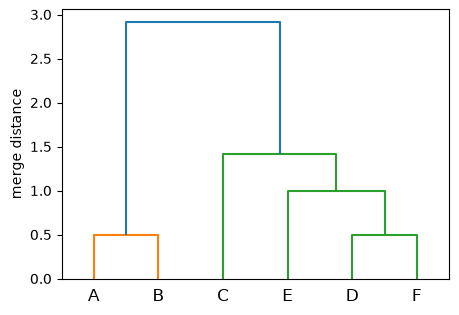

In [3]:
Z = linkage(P, method='single'); print('scipy merge heights :', Z[:, 2].round(3)); print('manual merge heights:', [m[2] for m in manual])
assert np.allclose(sorted(Z[:, 2]), sorted(m[2] for m in manual), atol=1e-3)
fig, ax = plt.subplots(figsize=(5, 3.5)); dendrogram(Z, labels=names, ax=ax); ax.set_ylabel('merge distance'); plt.show()

### Chaining effect
Single linkage links points through chains of close neighbours (merge distance = the closest pair), so it keeps a whole chain together and splits off only the isolated pair, giving a lopsided partition. Complete linkage (merge distance = the farthest pair) cuts the chain and gives balanced groups. Compare the two-cluster sizes below.

In [4]:
chain = np.array([[i * 1.0, 0] for i in range(8)] + [[0, 5], [0.5, 5.2]])
from scipy.cluster.hierarchy import fcluster
for method in ('single', 'complete'):
    lab = fcluster(linkage(chain, method), 2, 'maxclust'); print(method, 'two-cluster sizes:', np.bincount(lab)[1:])

single two-cluster sizes: [2 8]
complete two-cluster sizes: [4 6]


Single linkage on the Mall data (notebook 04) shows the same behaviour: it peels off a couple of outliers and its best silhouette is at k=2.